# How do company size, legal structure and owner qualification relate to the distribution and concentration of declared capital among Brazilian companies?

## 1. Data cleaning and summary

The dataset contains Brazilian companies, with one row per company, identified by a unique "company_id". Our main variable of interest is "capital_stock"(declared capital). We compare it across "company_size", "legal_nature" and "owner_qualification".

In [1]:
import pandas as pd 
import numpy as np 

In [2]:
companies = pd.read_csv("../data/companies.csv")
print(companies.shape)
print("missing values:", companies.isna().sum().sum())
print("duplicate IDs:", companies["company_id"].duplicated().sum())
print("capital stock less than or equal to 0:", (companies["capital_stock"]<= 0).sum())


(141332, 6)
missing values: 0
duplicate IDs: 0
capital stock less than or equal to 0: 0


### Data checks

The data has 141,332 companies and 6 columns. There are no missing values, no duplicate company IDs and no zero or negative capital values. "companies.csv" already contains the columns for size, legal nature and owner qualification, so the three other files ("size.csv", "legal_nature.csv", "qualifications.csv") did not need to be merged in.

In [3]:
# 99th percentile of capital
p99 = companies["capital_stock"].quantile(0.99)
print("99th percentile:", p99)

# which values repeat among the largest 1% of companies?
top = companies[companies["capital_stock"] > p99]
print(len(top), "companies above the 99th percentile")
print(top["capital_stock"].value_counts().head(5))

99th percentile: 207262732.90840003
1414 companies above the 99th percentile
capital_stock
5.000000e+08    416
1.000000e+11    184
6.000000e+08     40
2.000000e+10     26
1.000000e+12     23
Name: count, dtype: int64


### Placeholder values

Among the top 1% of companies, a few round figures repeat many times. For example, 184 companies declare exactly R$100 billion, 26 declare exactly R$20 billion and 23 declare exactly R$1 trillion. Real declared capital rarely repeats this precisely at such a scale, and several of these companies are small holding firms, so we treat these values as likely placeholders.

In [4]:
# strip whitespace in text columns
for col in ["company_name", "legal_nature", "owner_qualification", "company_size"]:
    companies[col] = companies[col].str.strip()

# flag the top 1% of companies by capital (kept in the data, not deleted)
companies["top1pct"] = companies["capital_stock"] > p99

# capped version: values above the 99th percentile are set to the cutoff
companies["capital_capped"] = np.where(companies["capital_stock"] > p99, p99, companies["capital_stock"])

print(companies["top1pct"].sum(), "companies flagged")

1414 companies flagged


### Cleaning and transformations

- **Whitespace:** We stripped leading and trailing whitespace from all text columns.
- **Placeholders:** We cannot tell exactly which large values are placeholders, since some very large companies actually do have large capital. So instead of deleting the extreme values, we flagged the top 1% of companies (those above the 99th percentile, about R$207 million) in a "top1pct" column. We also created "capital_capped", where values above that cutoff are set to the cutoff. This lets us compare results with and without the influence of the largest values.
- **Assumptions:** The size category "other" is not defined in the data. We assume it means companies larger than micro and small enterprises.

In [5]:
# skew and concentration of capital
print("median:", companies["capital_stock"].median())
print("mean:", companies["capital_stock"].mean())
top_firms = companies[companies["top1pct"]]
top_share = top_firms["capital_stock"].sum() / companies["capital_stock"].sum()
print("share of total capital held by top 1%:", top_share)

# capital by company size
print(companies.groupby("company_size")["capital_stock"].agg(["count", "median", "mean"]).reset_index())

# legal structure: number of firms and share of total capital, with and without the top 1%
firms_pct = companies["legal_nature"].value_counts(normalize=True)
capital_by_legal = companies.groupby("legal_nature")["capital_stock"].sum()
capital_share_all = capital_by_legal / companies["capital_stock"].sum()

trimmed = companies[~companies["top1pct"]]
capital_by_legal_trimmed = trimmed.groupby("legal_nature")["capital_stock"].sum()
capital_share_trimmed = capital_by_legal_trimmed / trimmed["capital_stock"].sum()

legal = pd.DataFrame({
    "firms_pct": firms_pct,
    "capital_share_all": capital_share_all,
    "capital_share_without_top1pct": capital_share_trimmed
})

print(legal.sort_values("capital_share_all", ascending=False).head().reset_index())

# owner qualification
print(companies["owner_qualification"].value_counts(normalize=True).head())

median: 400000.0
mean: 353697048.1669324
share of total capital held by top 1%: 0.9922747185532392
       company_size  count     median          mean
0  micro-enterprise  66202   300000.0  2.129195e+07
1             other  42520  1037169.0  5.004296e+08
2  small-enterprise  32610   350000.0  8.371934e+08
                               legal_nature  firms_pct  capital_share_all  \
0  Limited Liability Business Company (LLC)   0.844027           0.981718   
1                Privately Held Corporation   0.020498           0.009766   
2                       Sole Proprietorship   0.107612           0.003585   
3               Publicly Traded Corporation   0.000368           0.003290   
4                 Simple Innovation Company   0.001019           0.000691   

   capital_share_without_top1pct  
0                       0.667795  
1                       0.125439  
2                       0.158794  
3                       0.002724  
4                       0.000826  
owner_qualification


### Key summary statistics

**Distribution and concentration.** Declared capital is very uneven. The median company declares R$400,000, but the mean is about R$354 million, almost 900 times larger, because a few huge values pull it up. The top 1% of companies (1414 firms) hold about 99.2% of all declared capital, although much of this comes from the likely placeholder values described above.

**Company size.** Median capital rises with size: about R$300,000 for micro-enterprises, R$350,000 for small enterprises and R$1.04 million for other. However, small enterprises have the highest mean (about R$837 million, compared with about R$500 million for other), which is driven by a few extreme values rather than by typical small firms. Hence, we use medians and the capped values when comparing sizes.

**Legal structure.** About 84% of companies are limited liability business companies (LLCs), and they hold about 98.2% of total declared capital. Once the top 1% is removed, their share drops to about 66.8%, and sole proprietorships (15.9%) and privately held corporations (12.5%) become visible. So conclusions about legal structure depend heavily on how the extreme values are treated, and we report both versions.

**Owner qualification.** About 75.7% of companies list a Managing Partner / Partner-Administrator as their owner role, and the remaining companies are spread across many small categories.

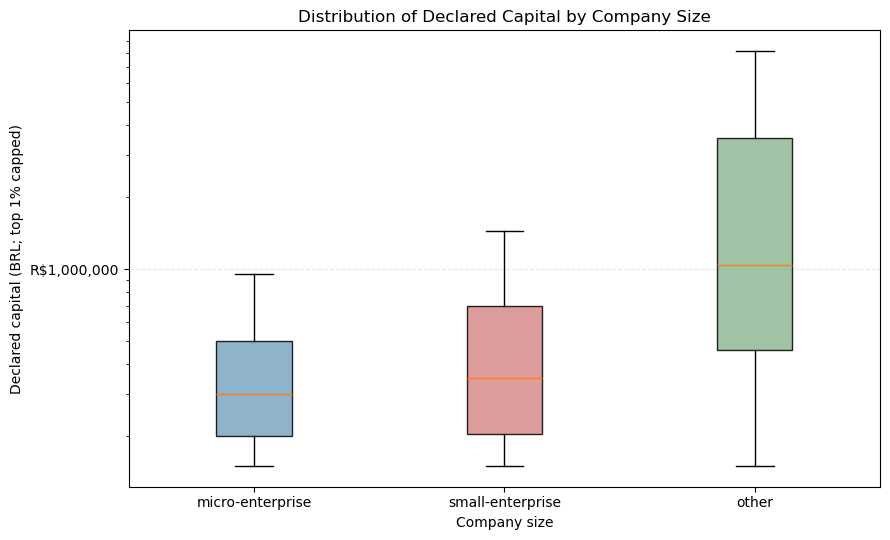

In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Plot 1: compare the distribution of declared capital across company sizes.
# The top 1% is capped to prevent extreme values from hiding the typical distribution.
size_order = ["micro-enterprise", "small-enterprise", "other"]
box_data = [
    companies.loc[companies["company_size"] == size, "capital_capped"]
    for size in size_order
]

fig, ax = plt.subplots(figsize=(9, 5.5))
box = ax.boxplot(box_data, patch_artist=True, showfliers=False)
for patch, colour in zip(box["boxes"], ["#7AA6C2", "#D98C8C", "#8FB996"]):
    patch.set_facecolor(colour)
    patch.set_alpha(0.85)

ax.set_title("Distribution of Declared Capital by Company Size")
ax.set_xlabel("Company size")
ax.set_ylabel("Declared capital (BRL; top 1% capped)")
ax.set_xticks(range(1, len(size_order) + 1))
ax.set_xticklabels(size_order)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"R${x:,.0f}"))
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


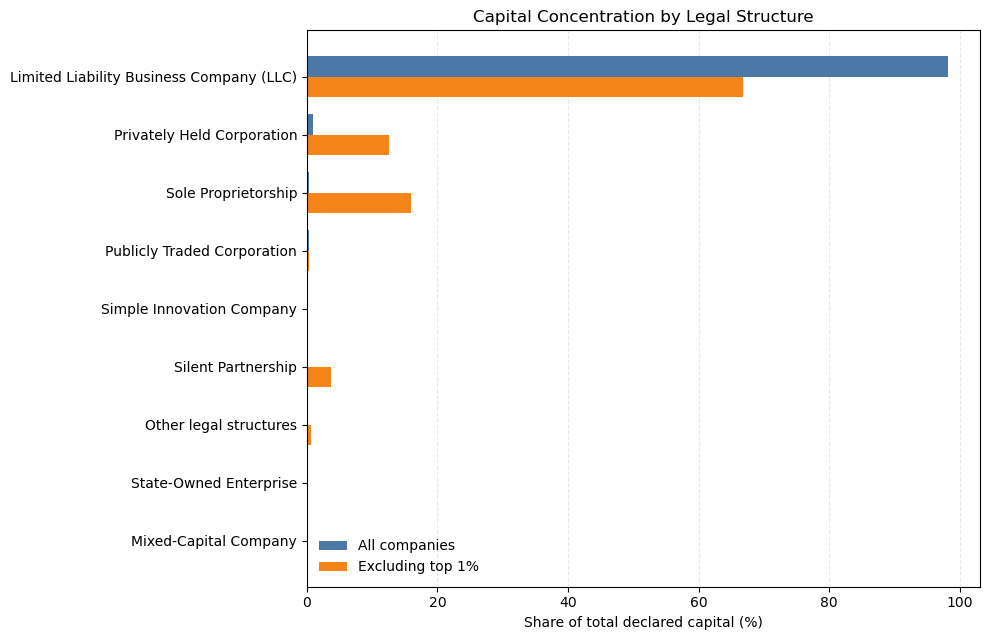

In [7]:
# Plot 2: compare how legal structures contribute to total capital.
# The second series is a sensitivity check excluding the top 1% of firms.
legal_rank = legal.sort_values("capital_share_all", ascending=False)
top_legal = legal_rank.head(8)[["capital_share_all", "capital_share_without_top1pct"]].copy()
other_legal = legal_rank.iloc[8:][["capital_share_all", "capital_share_without_top1pct"]].sum()
other_legal.name = "Other legal structures"
legal_plot = pd.concat([top_legal, other_legal.to_frame().T]).sort_values("capital_share_all")

y = np.arange(len(legal_plot))
bar_height = 0.36
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(y + bar_height / 2, legal_plot["capital_share_all"] * 100, height=bar_height, label="All companies", color="#4C78A8")
ax.barh(y - bar_height / 2, legal_plot["capital_share_without_top1pct"] * 100, height=bar_height, label="Excluding top 1%", color="#F58518")
ax.set_yticks(y)
ax.set_yticklabels(legal_plot.index)
ax.set_xlabel("Share of total declared capital (%)")
ax.set_title("Capital Concentration by Legal Structure")
ax.legend(frameon=False)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


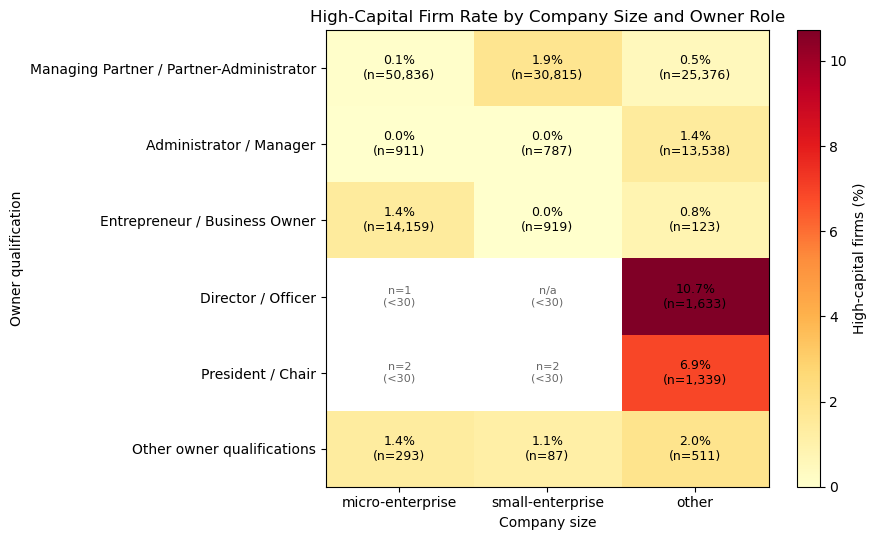

In [8]:
# Plot 3: identify which size-owner combinations contain high-capital firms most often.
# High-capital firms are defined as those above the overall 99th percentile.
top_roles = companies["owner_qualification"].value_counts().head(5).index.tolist()
owner_group = companies["owner_qualification"].where(
    companies["owner_qualification"].isin(top_roles),
    "Other owner qualifications"
)

combo = (
    companies.assign(owner_group=owner_group)
    .groupby(["owner_group", "company_size"], observed=False)
    .agg(total_firms=("company_id", "size"), high_capital_firms=("top1pct", "sum"))
)
combo["high_capital_rate"] = combo["high_capital_firms"] / combo["total_firms"]
role_order = top_roles + ["Other owner qualifications"]
rate = combo["high_capital_rate"].unstack().reindex(index=role_order, columns=size_order)
counts = combo["total_firms"].unstack().reindex(index=role_order, columns=size_order)
# Avoid drawing strong conclusions from combinations with very small samples.
rate_display = rate.where(counts >= 30)

fig, ax = plt.subplots(figsize=(9, 5.5))
vmax = np.nanmax(rate_display.to_numpy()) * 100
im = ax.imshow(rate_display * 100, cmap="YlOrRd", aspect="auto", vmin=0, vmax=vmax)
ax.set_xticks(range(len(size_order)))
ax.set_xticklabels(size_order)
ax.set_yticks(range(len(role_order)))
ax.set_yticklabels(role_order)
ax.set_xlabel("Company size")
ax.set_ylabel("Owner qualification")
ax.set_title("High-Capital Firm Rate by Company Size and Owner Role")
for i in range(rate_display.shape[0]):
    for j in range(rate_display.shape[1]):
        value = rate_display.iloc[i, j]
        n = counts.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value * 100:.1f}%\n(n={int(n):,})", ha="center", va="center", fontsize=9)
        else:
            count_label = "n/a" if pd.isna(n) else f"n={int(n):,}"
            ax.text(j, i, f"{count_label}\n(<30)", ha="center", va="center", fontsize=8, color="#666666")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("High-capital firms (%)")
plt.tight_layout()
plt.show()


## Preliminary discussion

**Plot 1 — Company size and capital distribution.** The boxplot compares declared capital across size categories. Median capital is R$300,000 for micro-enterprises, R$350,000 for small enterprises and about R$1.04 million for the `other` category. The latter also has a wider interquartile range. The meaning of `other` should not automatically be interpreted as large companies.

**Plot 2 — Legal structure and capital concentration.** LLCs account for about 98.2% of total declared capital. Excluding the highest-capital 1% of firms reduces their share to 66.8%, while sole proprietorships and privately held corporations account for 15.9% and 12.5%, respectively. LLCs dominate both samples, but the degree of concentration is sensitive to extreme values; excluding the top 1% does not establish that those records are errors.

**Plot 3 — Company size and owner qualification.** The heatmap compares the proportion of firms above the overall 99th-percentile capital threshold (about R$207.3 million). Within the `other` size category, 10.7% of firms with a Director / Officer role and 6.9% with a President / Chair role exceed this threshold. Combinations with fewer than 30 firms are masked. These rates use original capital values and may be affected by unusually large declarations.

**Overall.** Capital distributions differ across size categories, capital is concentrated in LLCs, and high-capital firms are more prevalent in certain size–owner-role combinations. These are associations within the supplied sample of firms with capital above R$150,000, rather than causal conclusions about all Brazilian companies.
